# Data Science Classification Task

In this notebook we will walk through an example of classifying data with a simple ML model. This process mainly consists of 4 steps:

1. **Data Exploration**
2. **Data Preparation**
3. **ML Model Training**
4. **Model Evaluation**

During each of these steps we will explain how to do them and the importance behind it.

## Import packages
Some necessary imports of functions we will use later...

In [6]:
import pandas as pd
import re, nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.sparse import hstack
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,confusion_matrix

# 1. Data Exploration

## 1.1 Import dataset

Before doing anything with the data, we need to first import it. It is also useful to first take a look at the columns that are present in the dataset.
The dataset is a collection of tweets about airlines and customer satisfaction, it also contains the label about the sentiment of the tweet (neutral, positive, negative). The dataset is a .csv file which we can usually open using Excel, but since we want to explore the dataset using Python we will open it using the Pandas library as a Dataframe.

In [7]:
# Read the dataset from a csv file
# Task: Fill in the correct path to the tweets dataset.
tweets_data = pd.read_csv("Tweets.csv")

# Look at the columns in our dataset
list(tweets_data.columns.values)

['tweet_id',
 'airline_sentiment',
 'airline_sentiment_confidence',
 'negativereason',
 'negativereason_confidence',
 'airline',
 'airline_sentiment_gold',
 'name',
 'negativereason_gold',
 'retweet_count',
 'text',
 'tweet_coord',
 'tweet_created',
 'tweet_location',
 'user_timezone']

## 1.2 What kind of data are we looking at?
Now that we roughly know what data is present in the dataset, we need to further examine it by taking a look at an excerpt of the dataset to better understand the nature of the data or more specifically their typing. Mainly discerning numerical columns (int or float) from categorical columns like string for example. Since string is an object type it will be displayed as object.

In [8]:
# Print the types of each column of our data
print(tweets_data.dtypes)

tweet_id                          int64
airline_sentiment                object
airline_sentiment_confidence    float64
negativereason                   object
negativereason_confidence       float64
airline                          object
airline_sentiment_gold           object
name                             object
negativereason_gold              object
retweet_count                     int64
text                             object
tweet_coord                      object
tweet_created                    object
tweet_location                   object
user_timezone                    object
dtype: object


In [9]:
# Look at the first 5 rows of our data
tweets_data.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


## 1.3 Which columns are possibly interesting for classification?
In theory one could choose any column with a categorical value and try to do classification on it but in reality there are only a few that make sense with the features that are available. To decide which classification task could be useful, one has to think about correlation between columns in the available dataset. Sometimes it's trivial and only requires some "common sense" or just simple curiosity and sometimes it requires good domain knowledge or specific goals that would pose questions of some sort about the data.

For example, if we take the name of the tweet's author there will be no correlation between the name and any other column in the dataset. But in contrast, if we take the tweet's text, there will be a correlation between the text and the tweet's sentiment, which makes sense because a tweet to an airline is most likely to communicate some sentiment in the form of text. There will, for example, also be a correlation between the tweet's text and the airline but this one is not as interesting since it's most likely by direct mention of the airline name or the airline's twitter account. 
So we will stick to the interesting classification we can do here, which is classifying the sentiment of a tweet by its text.

One crucial skill of a Data Scientist is being able to look at data and pose these kind of questions!

## 1.4 A bit more data exploration...
Since we now know which columns are most interesting for us, we can do some further data exploration on them. With the following code snippets we will take a look at the distribution of values for the most interesting categorical values, which are airline sentiment and important connected columns like the correspondng airline name and the customer service issue.

Total number of tweets: 14640

The distribution of the examined columns can be seen in the following pie charts:

In [10]:
# Save the number of tweets in a variable
n_tweets = tweets_data.tweet_id.count()

# Print the number of tweets with some explaining text
print(f'Number of tweets: {n_tweets}')

Number of tweets: 14640


### 1.4.1 Sentiment Distribution
A good start is to look at the distribution of sentiments among all tweets. In the pie chart below we can see that the majority of tweets is rather negative, which kind of makes sense, sine people are more inclined to publicly share their opinion after a negative experience than a positive experience.

<Axes: ylabel='Sentiments'>

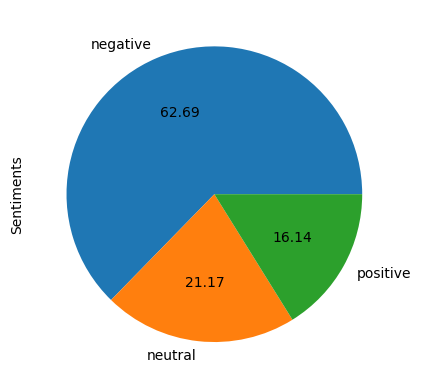

In [11]:
# Calculate the ratio for each sentiment, using the previously saved variable with the number of tweets
sentiment_ratio = tweets_data.airline_sentiment.value_counts(dropna=False)/n_tweets

# Rename the column from "airline sentiment" to "Sentiments"
sentiment_ratio = sentiment_ratio.rename("Sentiments")

# Create a pie chart from dataframe
sentiment_ratio.plot(kind='pie', autopct='%.2f')

### 1.4.2 Airline Distribution
Looking at the airline distribution is also interesting, so we can get a feeling of which airlines are present in our dataset.

**Your turn:** 
1. Write code for the column renaming (Hint: Take a look at the previous section 1.4.1)

<Axes: ylabel='count'>

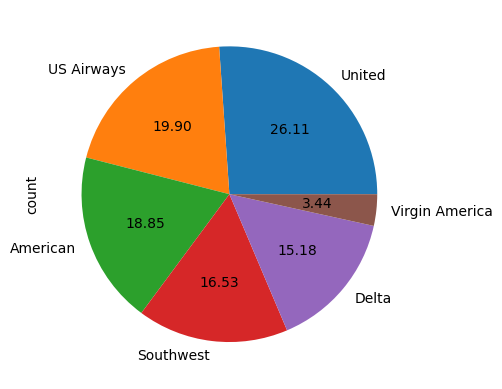

In [12]:
# Calculate the ratio for each airline, using the previously saved variable with the number of tweets
airline_ratio = tweets_data.airline.value_counts(dropna=False)/n_tweets

# Rename the column from "airline" to "Airline"
# Task: Write code for the column renaming (Hint: Take a look at the previous section 1.4.1)



# Create a pie chart from dataframe
airline_ratio.plot(kind='pie', autopct='%.2f')

We can also create a bar chart instead for better readability:

<Axes: xlabel='airline'>

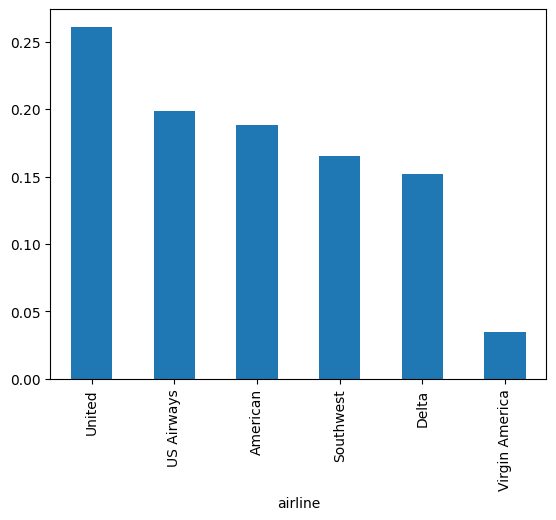

In [13]:
airline_ratio.plot(kind='bar')

### 1.4.3 Sentiment Reason Distribution
Lastly we will loook at the reasons for the corresponding sentiment that are present in the dataset, with which we can get an overview of the most common reasons for airline feedback. Also we can see that there is a good part of the data for which we don't have any reason at all.

**Your turn:** 
1. Write the code to calculate the ratio for each customer service issuse. (Hint: The relevant column here is "negativereason")

<Axes: ylabel='Reasons'>

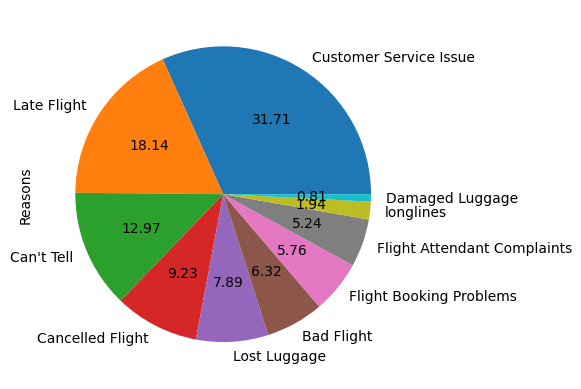

In [14]:
# Calculate the ratio for each customer service issue, using the previously saved variable with the number of tweets
# Task: Write the code to calculate the ratio for each customer service issuse. (Hint: The relevant column here is "negativereason")
n_negative_reasons = tweets_data[tweets_data.airline_sentiment == 'negative'].negativereason.count()
reason_ratio = tweets_data.negativereason.value_counts(dropna=True)/n_negative_reasons

# Rename the column from "negativereason" to "Reasons"
reason_ratio = reason_ratio.rename("Reasons")

# Create a pie chart from dataframe
reason_ratio.plot(kind='pie', autopct='%.2f')

We can also again create a bar chart instead for better readability:

<Axes: xlabel='negativereason'>

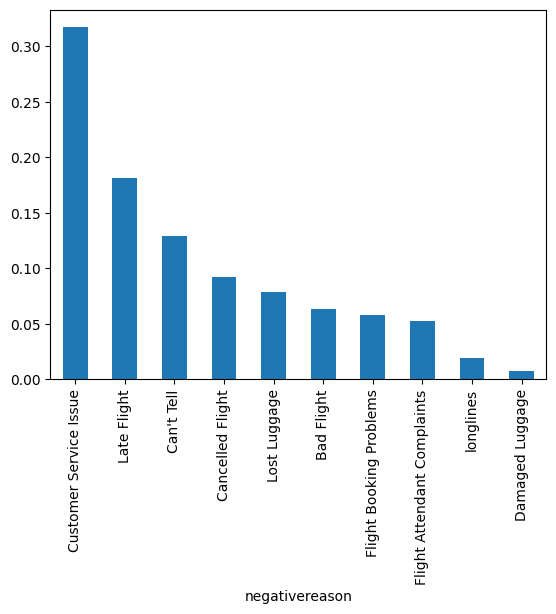

In [15]:
reason_ratio.plot(kind='bar')

### 1.4.4 Sentiment Distriubtion per Airline
But most interesting is the combination of both pie charts we have shown so far, the distribution of sentiment depending on the airline. This gives us some valuable business information as a customer could already use this to decide for airlines with better customer satisfaction.

<Axes: xlabel='airline'>

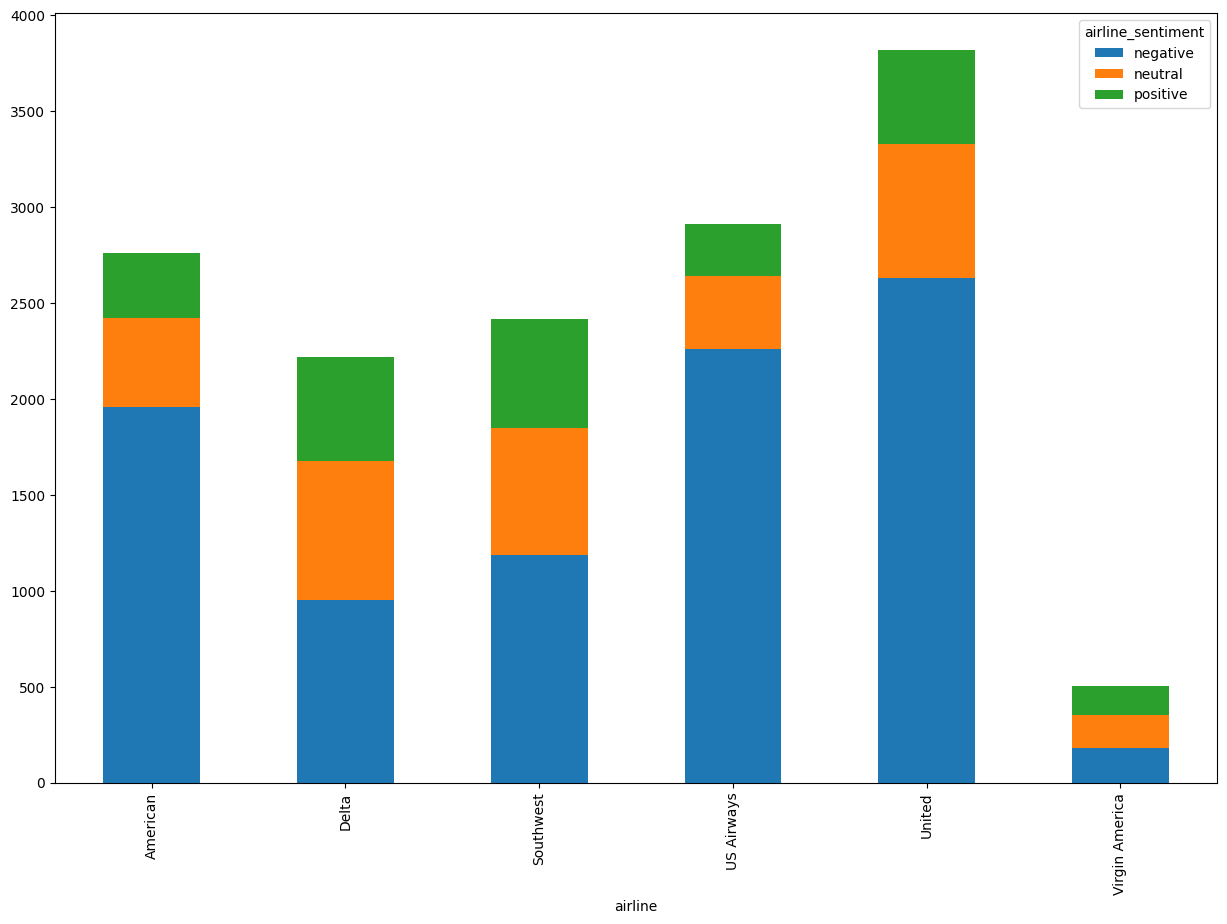

In [16]:
# Group data by airlines and sentiment and count them
airline_sent = tweets_data.groupby(['airline', 'airline_sentiment']).size()

# Create a bar chart from the grouped data
airline_sent.unstack().plot(kind='bar', stacked=True, figsize=(15,10))

# 2. Data Preparation
We now have a good feeling about the nature and content of our data, based on this information we need to do some preparation of the data, so we can later train an ML model on it. Given that the main feature we want to do classification on is a tweet which is textual, we need to do appropriate preparation for textual data. Given a tweet, we will normalize it by:

1. Filtering the tweet content so it only contains letters
2. Tokenize the words inside the tweet
3. Make all the letters lowercase
4. Lemmatize all words, which means that we will reduce each word to its basic dictionary form, its "lemma"

All these steps serve the purpose of reducing complexity of the problem at hand, by stripping the data of its contents that don't provide more information that is useful for classification. Reducing complexity of problmes is a key part of ML, because reduced complexity increases the likelihood of being able to successfully train an ML model.

In [17]:
nltk.download('omw-1.4')
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
wordnet_lemmatizer = WordNetLemmatizer()

def normalize(tweet):
    only_letters = re.sub("[^a-zA-Z]", " ",tweet) 
    tokens = nltk.word_tokenize(only_letters)

    lower_case = [l.lower() for l in tokens]

    filtered_result = list(filter(lambda l: l not in stop_words, lower_case))

    lemmas = [wordnet_lemmatizer.lemmatize(t) for t in filtered_result]

    return " ".join(lemmas)

[nltk_data] Downloading package omw-1.4 to /Users/U776856/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/U776856/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /Users/U776856/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/U776856/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [18]:
# Apply the previously defined noromalize function
tweets_data['normalized_tweet'] = tweets_data.text.apply(normalize)

# Display the first 5 normalized tweets and the original text to check if function worked
tweets_data[['text','normalized_tweet']].head()

,text,normalized_tweet
0,@VirginAmerica What @dhepburn said.,virginamerica dhepburn said
1,@VirginAmerica plus you've added commercials t...,virginamerica plus added commercial experience...
2,@VirginAmerica I didn't today... Must mean I n...,virginamerica today must mean need take anothe...
3,@VirginAmerica it's really aggressive to blast...,virginamerica really aggressive blast obnoxiou...
4,@VirginAmerica and it's a really big bad thing...,virginamerica really big bad thing


# 3. ML Model Training
The data is now cleaned up and ready for processing... I would like to say but we are still missing a few steps. But since the next steps are more specific to the ML model we want to train we will include these in the ML model training section instead of having it in the general data preparation part.

## 3.1 Encoding the data
At the end of section 2 we were still dealing with text but what the computer is best at is working with numbers!  So we need to encode the text, in other words, we need to transform the text to numbers.

Before doing so, it is important to keep in mind that there is not just one way of encoding text, there are many different ways which may have advantages or disadvantages in certain scenarios and exploring these is a big topic on its own, so just remember that there are different ways of which many are probably better than the following, but here we will focus on understanding the concepts and go with a simple but yet effective approach. The key takeaway of this section being, that we go from text to numbers so we can do some sophisticated calculations.

### 3.1.1 Label Encoding
First, we will encode the labels (negative, neutral and positive). We only have 3 labels and for converting these to a number there is the very natural approach of assigning them the numbers 0, 1 and 2. So we now have 0 for negative, 1 for neutral and 2 for positive.

**Your turn:** 
1. Write the code to display the first 5 airline sentiments and their encoding (Hint: Check Section 2 where we did something similar)


In [19]:
# Create a label encoder for our data
labelenc = LabelEncoder()
labelenc.fit(tweets_data['airline_sentiment'])

# Apply the label encoder on data
tweets_data['airline_sentiment_encoded'] = labelenc.transform(tweets_data['airline_sentiment'])

# Check original labels and their encoding to check encoding function
# Task: Write the code to display the first 5 airline sentiments and their encoding (Hint: Check Section 2 where we did something similar)


### 3.1.2 Feature Encoding
The feature we want to use for classification is the text, which we now want to convert to numbers. In contrast to the encoding of labels, the structure and content of tweets is way more complex and we can't just assign a number to each distinct tweet, so we will use a different approach. Keep in mind, there is not just one solution to this problem, there are many different ways in which one could solve this.

The approach we choose for this example is using a count vector, which is a very simplistic solution to this problem:  
We basically create a vector (a sequence of numbers) that is as big as the vocabulary for all tweets, for example, if the vocabulary of all tweets in the dataset has a size of 500 words, we would create a vector of the size 500 in which each number corresponds to how often a word appeared in a single tweet.

One has to keep in mind that simplifying data in such a way comes at a cost. If we only take into account the number of occurences of a word in a tweet, we lose information about the order of words, since our new representation doesn't have this information anymore. If the simplification is worth losing this kind of information, one could just continue, but if losing the information about the order of words is crucial to solving our problem, then one would have to look for another way of encoding the tweets that would preserve this information. Making this kind of decisions is also a key skill of a Data Scientist and making "good" or "bad" trade-offs can often heavily impact performance of ML models. The trade-off also doesn't necessarily have to be about losing some information for the sake of keeping other information, it can also just be about computing resources and time, impacting the feasability of solving many problems.



**Your turn:** 
1. Write code to apply the count vectorizer to the normalized_tweet column. (Hint: Check the previous section 3.1.1) Also instead of assigning the result to a new column we will assign it to the variable x.

In [25]:
# Create a vectorizer for the text data
count_vectorizer = CountVectorizer(ngram_range=(1,2))
count_vectorizer.fit(tweets_data['normalized_tweet'])

# Apply the vectorizer to tweets
# Task: Write code to apply the count vectorizer to the normalized_tweet column. (Hint: Check the previous section 3.1.1)
# Also instead of assigning the result to a new column we will assign it to the variable x.
x = count_vectorizer.transform(tweets_data['normalized_tweet'])

y = tweets_data['airline_sentiment_encoded']

x.shape

(14640, 97131)

## 3.2 Train-Test Split
The data we use to train/fit the ML model is called training data, it's the example data points our model can take to learn patterns and extract meaningful information from the data. After training the model we would like to know how well the model performed, so we can simply just give it some data and check how well it is doing classification on said data. 

But we don't want to just give any data, we want to give the model data it has not seen before, because we want to check how well it can generalize from the data it has seen to new examples that were not present in the dataset. To achieve this, we just split the available data into a training dataset and a testing data set. With this we can train the model on one dataset and evaluate the model on another one. 

One question regarding this split is often on how to decide the train/test data ratio. There are many approaches that discuss this question, but the general rule is that we try to use as much data as possible that allows for the best generalization. If we use too much training data, we may risk being very good at classifying samples from the training data but not generalize well for new examples. On the other side if we use too much data for testing, it may happen that the training data is not sufficient to learn anything useful. In our case we will use a simple train-test split of 75% training data and 25% testing data.

In [26]:
# Split data into training and testing dataset
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=42)

print(x_train.shape)
print(y_train.shape)

print(x_test.shape)
print(y_test.shape)

(10980, 97131)
(10980,)
(3660, 97131)
(3660,)


## 3.3 Choosing the correct ML model
This is one of the harder parts of a Data Science project. The number of different ML models is vast and always increasing, as the research in the field of AI is very active and one that is evolving all the time, so deciding on the correct ML model can feel very overwhelming. Most ML models are in general better suited for some domains and not a good fit for other domains. Some are very sophisticated and complex, while others are more simplistic in nature. For many one can't even reason much about what's leading the model to a decision, as the innerworkings are often some high dimensional calculations of matrices, making it some kind of blackbox for which we only look at how well this blackbox performs. 

We will avoid going into too much detail about which ML models exist and how to navigate the decision on when to pick which model, because this alone is a very big topic which would require a lot more background knowledge which is out of scope for this tutorial. But as a general rule it is good to know, that there often are many different options depending on the scenario and it's not always wise to go for the model with for example the highest accuracy, as one should also consider simplicity and the available resources and time for a good choice.

## 3.4 Support Vector Machine (SVM)
So for this tutorial we will use a Support Vector Machine (SVM), in short an SVM tries to learn a line that best seperates two sets of datapoints. If we look at the first image we can see two sets of datapoints, blue and green points. The goal now is to find a line that seperates these two colors.

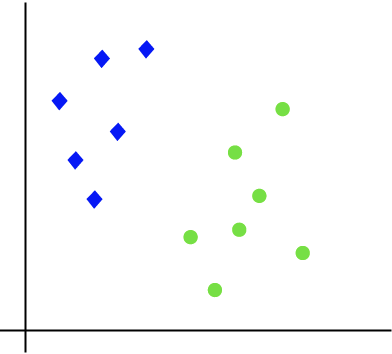 

But as we can see in the second image, there are multiple lines we could use to seperate these datapoints, so which one do we choose?

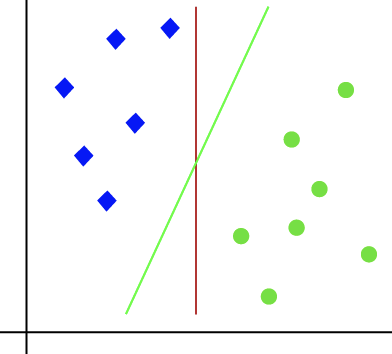 

This is where SVMs come to use, SVMs try to find the best seperating line by finding the closest points of both classes to the line and maximizing the distance to them. These points are called support vectors, hence the name Support Vector Machine. The line with the maximum distance to the support vectors is called optimal hyperplane. There is a lot of math going on "behind the scenes" in finding this optimal line and it is certainly helpful and good to have some understanding of it, especially when it comes to limitations of the model, but for the sake of this tutorial we will stick with the visual explanation to give an easy introduction. 

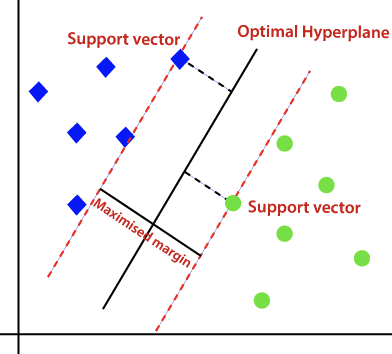

## 3.3 Training the SVM
Since the data is ready to be processed, we can use our training data to fit the ML model. It doesn't look like there is much happening since it's only two lines of code, but this is where all the Machine Learning "magic" is happening, involving lots of math. It's just kind of hidden behind the initialization of the model and the fit function.

**Your turn:** 
1. Initialize the SVM (SVC is one kind of SVM)

2. Train the SVM on our training data

In [29]:
# Task: Initialize SVM (SVC is one kind of SVM)
svm = SVC(kernel='linear',random_state=10)

# Task: Train the SVM on our training data
svm.fit(x_train, y_train)


,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


## 3.5 Evaluating the SVM
We have now trained our ML model and want to check how well it performs. We discussed in Section 3.2 already that we split our data in training and testing data. The training data we just used for training, so now as the name already suggests, we need to use the testing data for testing the model. For this, we basically just take the testing data and let the model predict the labels based on the input features, which in this case are the tweets, and we of course withold the information about the actual labels. Then we can use the predicted labels and compare them to the actual labels to check if our model did a good job. As we can see in the evaluation we achieved an accuracy of around 78%, meaning through our predictions on the testing data the model was correct 78% of the time, which is a good result.

**Your turn:** 
1. Use the trained SVM model to make predictions on testing data

In [32]:
# Task: Use the trained SVM model to make predictions on testing data
pred = svm.predict(x_test)


# Calculate the accuracy score of the model, using the true labels and the predictions
accuracy = accuracy_score(y_test,pred)
print(f'The accuracy score is {accuracy}')

The accuracy score is 0.7770491803278688


### 3.5.1 Confusion Matrix
Accuracy is not the only metric we can look at, we can also take a look at the confusion matrix. It gives us information on which labels get mistaken for which. It is not always wise to only look at the accuracy, because sometimes the model can achieve "good" accuracy without actually being good for our business case. For example if label distribution is heavily skewed towards one label, let's say 80% negative labels, 10% neutral and 10% positive, the model could learn to only predict negative and thus achieve an accuracy of 80%, which would seem good at first glance but the reality is that the model just exploited to statistical distribution of labels, because if it only predicts negative it will be right 80% of the time, since 80% of the labels are negative to begin with. This is also why the initial data exploration is important, so we can know when the model only exploits statistical distributions and when it actually uses the features for its prediction. There still are different metrics we could use, depending on what we actually want to achieve but we will leave this out for this tutorial, because in our case the current metrics are good enough.

**Your turn:** 
1. Create confusion matrix
2. Transform confusion matrix to DataFrame

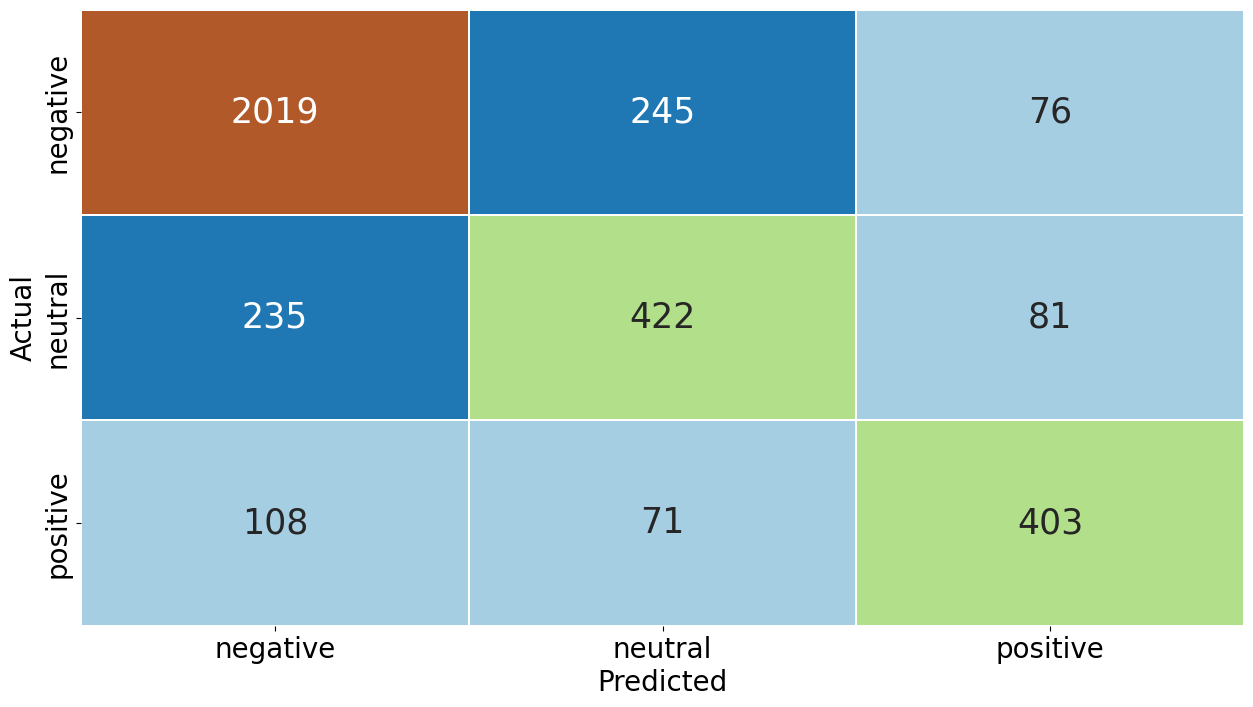

In [35]:
# Task: Create confusion matrix

conf_matrix = confusion_matrix(y_test, pred)

# Defining the size of the canvas
plt.rcParams['figure.figsize'] = [15,8]
 
# Transform confusion matrix to DataFrame
cols = ['negative', 'neutral', 'positive']
conf_matrix = pd.DataFrame(data = conf_matrix,columns = cols, index = cols)


# Defining the size of the canvas
plt.rcParams['figure.figsize'] = [15,8]

# Plotting the confusion matrix
sns.heatmap(conf_matrix, annot = True, fmt = 'd', cmap = 'Paired', cbar = False,linewidths = 0.1, annot_kws = {'size':25})
plt.xlabel("Predicted", fontsize=20)
plt.ylabel("Actual", fontsize=20)
plt.xticks(fontsize = 20)
plt.yticks(fontsize = 20)
plt.show()